# 04 · Evaluation and error analysis (test slice, days 70-90)

Generated figures live in `report/figures/`; this notebook recomputes the key ones and digs into errors.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kronos_ml.config import load_config, DATA_DIR, MODELS_DIR, REPORT_DIR
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
cfg = load_config()

In [2]:
from IPython.display import Image, Markdown
res = json.loads((REPORT_DIR / "results.json").read_text())
comp = pd.DataFrame(res["comparison"]).set_index("model")
comp[["roc_auc", "pr_auc", "precision@thr", "recall@thr", "f1@thr", "alert_rate@thr", "precision@top2%", "recall@top2%",
      "missed_fraud_amount", "total_cost"]].round(3)

,roc_auc,pr_auc,precision@thr,recall@thr,f1@thr,alert_rate@thr,precision@top2%,recall@top2%,missed_fraud_amount,total_cost
model,,,,,,,,,,
zscore_baseline,0.921,0.468,0.259,0.674,0.374,0.052,0.232,0.467,32036.63,61646.63
isolation_forest,0.982,0.750,0.485,0.809,0.606,0.034,0.679,0.674,18160.47,37120.47
lof,0.974,0.741,0.696,0.698,0.697,0.020,0.701,0.697,25424.19,36824.19
ocsvm,0.974,0.705,0.302,0.835,0.444,0.056,0.643,0.638,12612.81,44037.81
ensemble,0.986,0.822,0.531,0.844,0.652,0.032,0.764,0.759,12934.63,31009.63


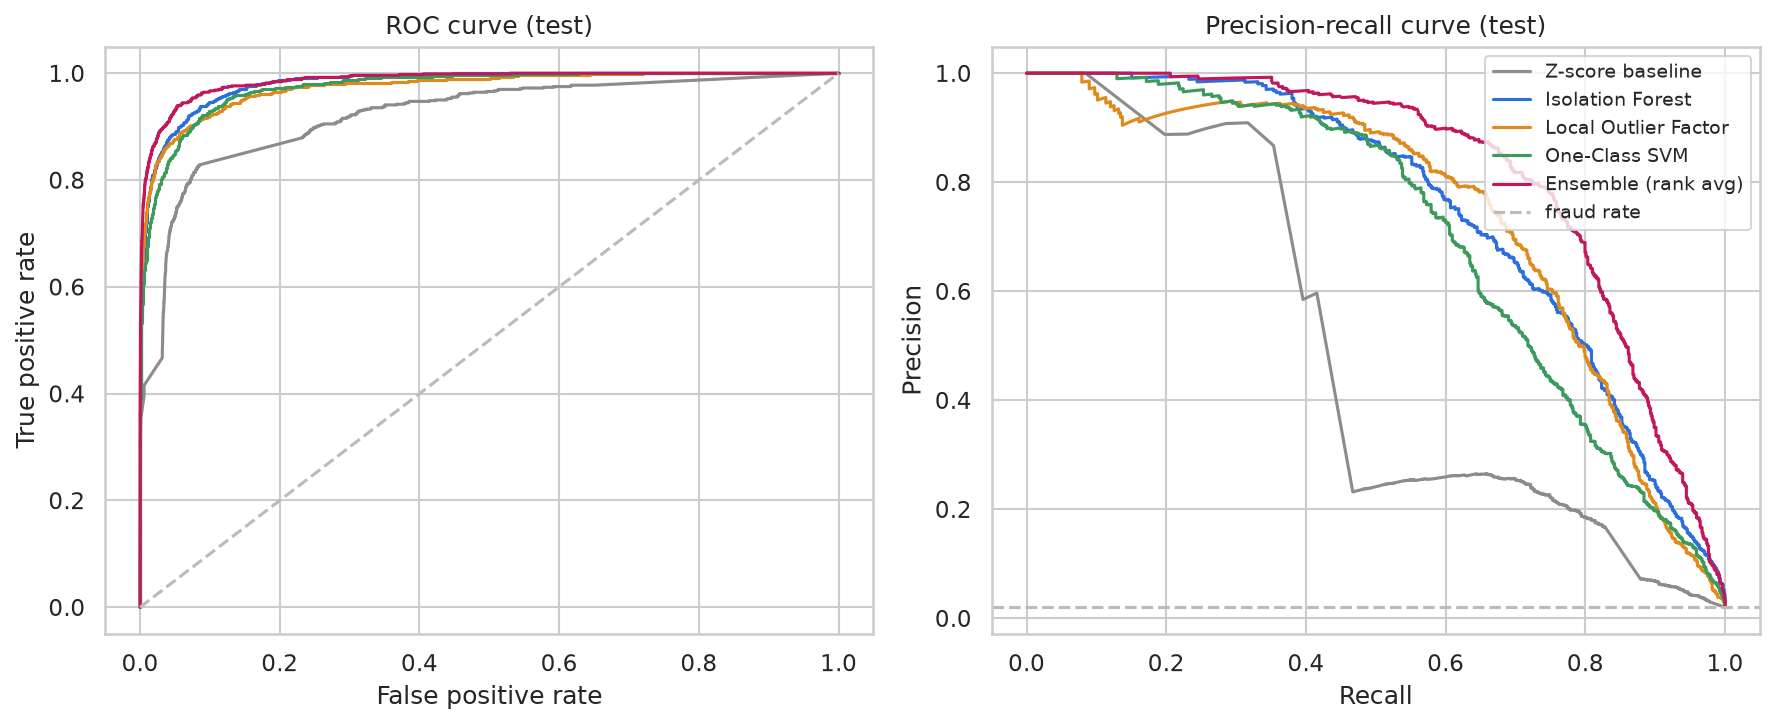

In [3]:
Image(REPORT_DIR / "figures" / "roc_pr.png")

In [4]:
pd.DataFrame(res["pattern_recall"]).round(2)

,layering,micro_drain,mule_fan_in,new_account_burst,odd_hour_spike,whale
zscore_baseline,0.52,0.95,0.33,0.80,0.82,0.82
isolation_forest,0.56,0.95,0.91,1.00,0.77,0.80
lof,0.38,0.90,0.85,0.99,0.50,0.75
ocsvm,0.56,0.93,0.94,1.00,0.76,0.92
ensemble,0.58,0.98,0.93,1.00,0.79,0.90


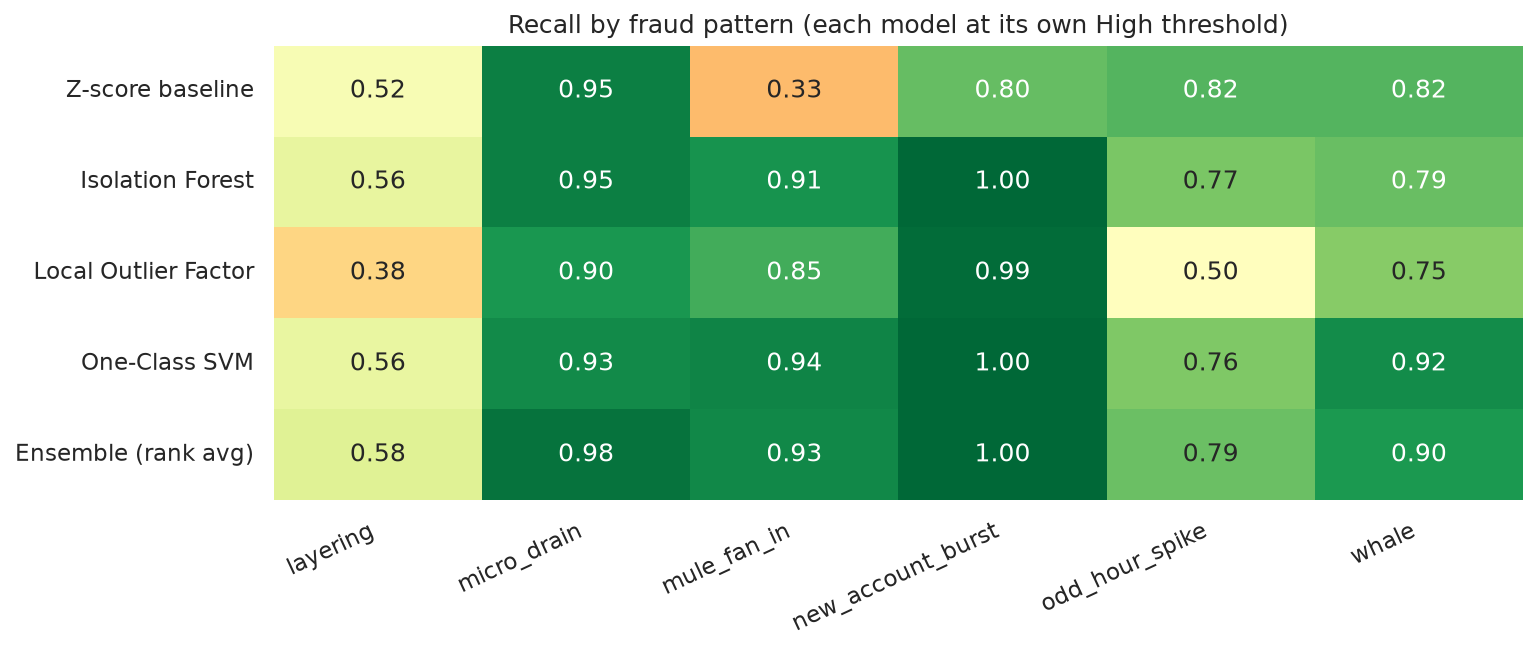

In [5]:
Image(REPORT_DIR / "figures" / "pattern_recall.png")

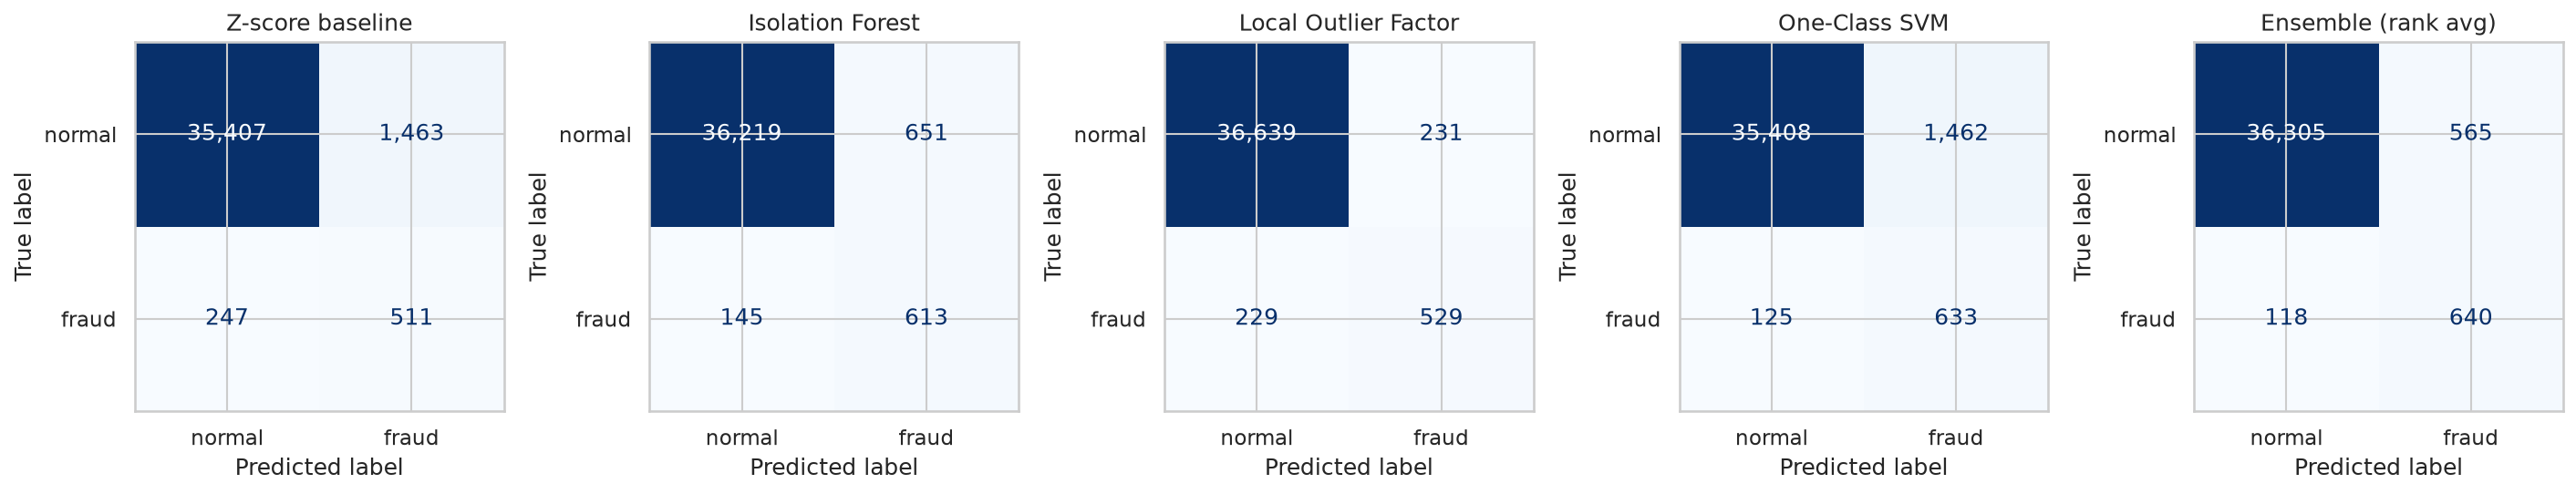

In [6]:
Image(REPORT_DIR / "figures" / "confusion.png")

### What does the deployed model miss, and what does it wrongly flag?

In [7]:
import joblib
from kronos_ml.models.train import load_features, split
from kronos_ml.features.build import FEATURES
parts = split(load_features(), cfg)
test = parts["test"].copy()
bundle = joblib.load(MODELS_DIR / "deployed.joblib")
test["raw"] = bundle["detector"].raw(test)
test["score"] = bundle["calibrator"](test["raw"])
test["flag"] = test["score"] >= 0.8
missed = test[(test.is_fraud == 1) & ~test.flag]
false_alarms = test[(test.is_fraud == 0) & test.flag]
print(f"missed {len(missed)} of {int(test.is_fraud.sum())} fraud rows; {len(false_alarms)} false alarms out of {int((test.is_fraud == 0).sum()):,} normal rows")
missed.fraud_type.value_counts()

missed 118 of 758 fraud rows; 565 false alarms out of 36,870 normal rows


fraud_type
layering          64
odd_hour_spike    27
whale             15
mule_fan_in       10
micro_drain        2
Name: count, dtype: int64

In [8]:
show = ["fraud_type", "amount", "score", "amount_to_median", "tx_10m", "new_receiver", "cycle_3hop_60m", "passthrough_ratio", "hour_rarity"]
missed[show].groupby("fraud_type").median().round(2)

,amount,score,amount_to_median,tx_10m,new_receiver,cycle_3hop_60m,passthrough_ratio,hour_rarity
fraud_type,,,,,,,,
layering,105.15,0.64,1.49,0.0,1.0,0.0,0.97,0.14
micro_drain,9.15,0.47,-1.13,0.0,1.0,0.0,0.00,0.94
mule_fan_in,48.22,0.54,0.39,0.0,1.0,0.0,0.00,0.21
odd_hour_spike,44.31,0.49,0.69,0.0,1.0,0.0,0.00,0.96
whale,27.25,0.59,-0.14,0.0,1.0,0.0,0.00,0.00


**Why layering is hard.** Each hop of a laundering ring is one ordinary-looking transfer to a new contact.
Only the *first* hop is unusual in amount, and only the *closing* hop shows the 3-hop cycle. The middle
hops are only caught through `passthrough_ratio` (forwarding money just received). Graph features over the
whole transfer network would be the next step (see Future work).

In [9]:
false_alarms[show[1:]].describe().T[["mean", "50%"]].round(2)

,mean,50%
amount,35.70,16.47
score,0.86,0.85
amount_to_median,-0.37,-0.05
tx_10m,0.31,0.00
new_receiver,0.27,0.00
cycle_3hop_60m,0.00,0.00
passthrough_ratio,0.44,0.00
hour_rarity,0.18,0.00


False alarms are mostly genuine but unusual behaviour: a large first payment to a new contact, or a burst of activity. A bank's analyst queue exists exactly for these.

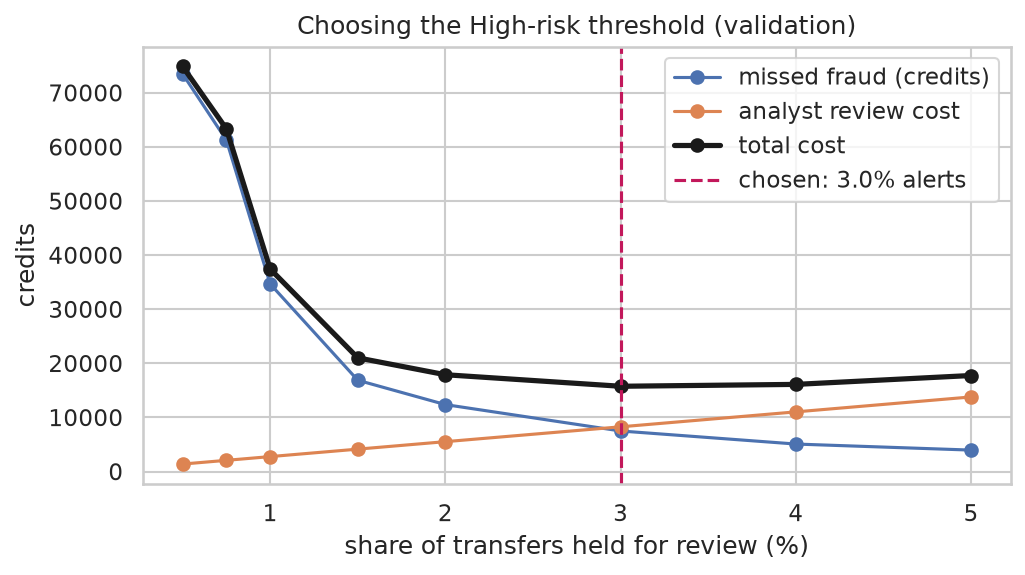

In [10]:
Image(REPORT_DIR / "figures" / "cost_curve.png")

### Robustness: lower fraud rates and other seeds

In [11]:
rob = pd.read_csv(REPORT_DIR / "robustness.csv")
rob.groupby(["fraud_rate", "model"]).pr_auc.agg(["mean", "std"]).unstack("model").round(3)

mean                                                     std                                               
model      ensemble isolation_forest    lof  ocsvm zscore_baseline ensemble isolation_forest    lof  ocsvm zscore_baseline
fraud_rate                                                                                                                
0.001         0.386            0.340  0.510  0.420           0.269    0.389            0.386  0.293  0.338           0.321
0.005         0.701            0.558  0.700  0.637           0.324    0.054            0.099  0.038  0.061           0.101
0.020         0.805            0.740  0.748  0.727           0.513    0.042            0.063  0.066  0.054           0.083

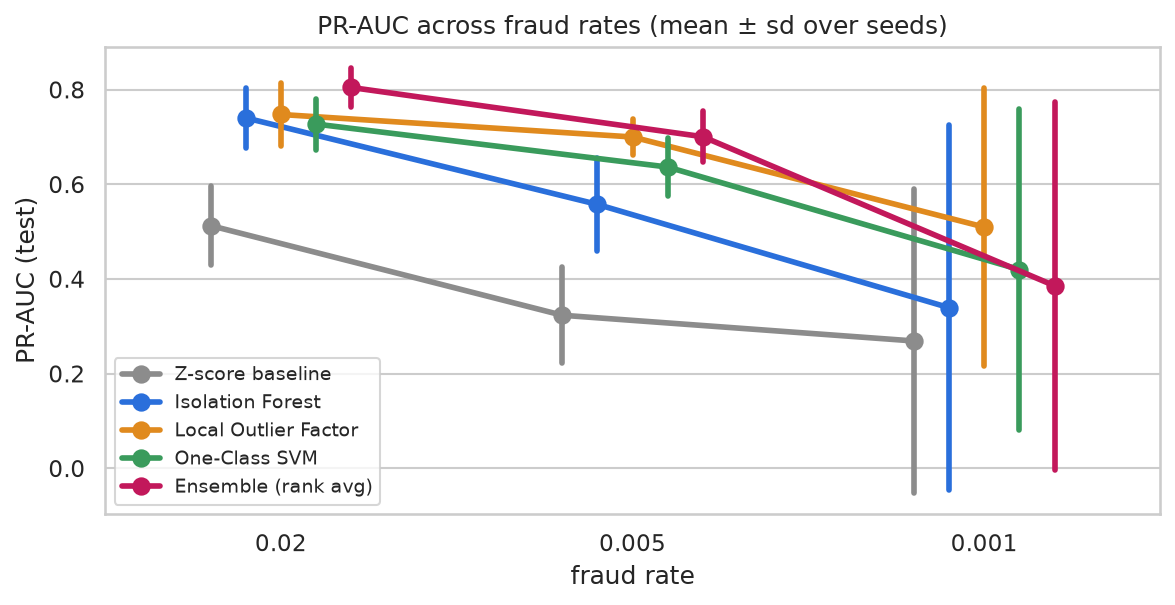

In [12]:
Image(REPORT_DIR / "figures" / "robustness.png")

PR-AUC falls as fraud gets rarer (the random baseline *is* the fraud rate), but the ranking of models
and the gap to the z-score baseline hold. ROC-AUC barely moves, which is why PR-AUC is the headline metric.